# Week 44, Tuesday session: cross-validation for your Project 2 network

**FYS-STK3155/4155, Tuesday October 27, 2026 — flipped classroom**

This notebook accompanies the Tuesday deck (`week44tuesday.pdf`). The
session has three parts:

- **Part A (about thirty minutes, a regular lecture):** the theory of
  cross-validation in one pass — summarised below so that you can read it
  again while you work.
- **Case 1 (about twenty minutes):** the six pencil-and-paper
  questions of exercise 1 of `exercisesweek44.ipynb`, in groups, then the
  answers in plenum. Write your answers in the cell provided; the answers
  we hope for are at the end of this notebook — read them *after* the
  plenum.
- **Case 2 (about thirty-five minutes):** your own network wrapped as a
  `scikit-learn` estimator inside `KFold`, `cross_validate`, `GridSearchCV`
  and `validation_curve`, on the Runge regression of Project 2 — exercise 2
  of this week, in six steps with checkpoints. The week-41 network is used
  here so that every cell runs; replace it by your Project 2 code in the
  exercises. **Required** in the exercises and in Project 2 is the
  cross-validation of the learning rate $\gamma$ and the penalty $\lambda$
  in front of the $L_2$ or $L_1$ norm (step 3); cross-validating the width,
  the depth, the activation and the number of epochs (step 4) is
  **optional** in both — it is shown here so that you know how.

At the end, only a mention: how the same is done with PyTorch and Keras.
Writing the cross-validation loop yourself is optional (exercise 4); the
exercise notebook shows it, checked against the library to every digit.

Seeds: 2026 for the data and the network, `KFold(5, shuffle=True,
random_state=2026)` for every fold. The whole notebook runs in about three
minutes. Deadline for the exercises: **Friday October 30**; Project 2:
**November 6**.

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_score, cross_validate, GridSearchCV, validation_curve

BLUE, RED, YELLOW, GREY = "#004488", "#BB5566", "#DDAA33", "#777777"
GREEN = "#228833"
SEED = 2026
np.set_printoptions(precision=4, suppress=True)

## Part A: the theory, in one page

**Three errors, three data sets (Sections 2.9, 3.14).** The parameters
(weights and biases) are fixed by minimising the cost on the training data
at fixed hyperparameters. The hyperparameters — $\lambda$, the learning rate
$\gamma$, the width, the depth, the number of epochs, the batch size — cannot
be fixed the same way, because the training error is non-decreasing in
$\lambda$ (Eq. 3.91) and falls with every hidden unit and every epoch:
minimising it over the hyperparameters returns the unpenalised, widest,
longest-trained network. Hence three errors kept apart: the *training error*,
minimised over the parameters; the *cross-validation error*, minimised over
the hyperparameters; the *test error*, computed once at the end and
minimised over nothing. And three data sets: the test set, set aside first
and not looked at until the last step; the training data, inside which
everything else happens; and the validation fold, the part of the training
data that plays the test set's role while choices are made.

**The $k$-fold estimate (Section 2.12, Eq. 3.92).** Shuffle, cut into $K$
folds, hold each out in turn, fit on the rest, predict the held-out fold:

$$
\mathrm{CV}_K=\frac{1}{n}\sum_{i}\bigl(y_i-\hat f^{(-\kappa(i))}(x_i)\bigr)^2
=\frac{1}{K}\sum_{k=1}^{K}\mathrm{MSE}_k ,
$$

the average error of every observation predicted by the model that did not
see it. It estimates the expected error on unseen data of the *training
procedure* applied to training sets of size $n(K-1)/K$ — not of the one
network you finally train on all $n$ points; the $K$ fold models are
temporary and discarded, and the final model is a new fit on all the
training data. Small $K$ is pessimistic (fold models see little data);
$K=n$ (leave-one-out, the jackknife of Eq. 2.53) has no such bias and no
fold randomness but $n$ almost identical training sets and a high-variance
estimate; $K=5$ or $10$ is the compromise. For classification, cut within
each class (`StratifiedKFold`).

**The standard error and why it is optimistic (Eq. 3.93).**
$\mathrm{SE}_K=s/\sqrt K$ with $s$ the standard deviation of the $K$ fold
errors — a rough guide, not a confidence interval: two training sets share a
fraction $(K-2)/(K-1)$ of their points, the fold errors are positively
correlated, and the formula understates the uncertainty. A library detail:
`GridSearchCV` reports `std_test_score` with `ddof=0`, so the standard error
is `std_test_score / np.sqrt(K - 1)`; and every score is a *negative* MSE,
because the library maximises.

**The one-standard-error rule (Eq. 3.96).** Near its minimum the CV curve is
flat and the position of the minimum is known only to within the noise.
Among the hyperparameters whose CV errors are within one standard error of
the best, take the simplest: the largest $\lambda$, the fewest hidden units,
the fewest epochs. The improvement of the more complex model is not larger
than the uncertainty with which it is measured, so it is not believed. Then
*refit* at the chosen values on all the training data (`best_estimator_`).

**Leakage (Section 3.14).** The held-out fold must be treated exactly as
future data: nothing computed from it may enter the fit. Any preprocessing
that learns from the data — scaling, feature selection, PCA — is fitted
inside each fold on the training part only. Scale the whole training set
once and every training fold has seen the mean and variance of its own
validation fold; for scaling the leak is small, for anything that looks at
the targets it is large. The mechanism is the `Pipeline`:
`make_pipeline(StandardScaler(), YourNet())`, cross-validated as a whole;
hyperparameters are addressed as `yournet__gamma`.

**The hyperparameters of a network (Section 8.12).** $\gamma$, $\lambda$,
width, depth, activation, batch size, dropout — and the **number of
epochs**: the training error falls with every epoch and says nothing, the
validation error falls, flattens and may rise, and the epoch at which it is
smallest is the chosen one (early stopping). A *validation curve* varies one
hyperparameter with the others fixed and shows CV and training error
against it, with error bars. The best CV score of a grid is *optimistic*
(the minimum of many noisy estimates), which is what the test set, touched
once, is for.

**What `scikit-learn` provides.** `KFold`/`StratifiedKFold` make the folds;
`cross_val_score` returns the $K$ fold scores, `cross_validate` also the
training scores and times; `GridSearchCV` runs the grid, stores everything
in `cv_results_` and refits the winner as `best_estimator_`;
`validation_curve` varies one hyperparameter; `learning_curve` varies the
training size; `cross_val_predict` gives out-of-fold predictions;
`Pipeline` keeps the scaler inside the fold. All it asks of your code are
three rules: `__init__` stores its keyword arguments under the same names
and does nothing else; `fit(X, y)` does the work, stores results in
attributes ending in `_`, and returns `self`; `predict(X)` returns a 1D
array.

## Part A, a worked example: Ridge on the Runge data, the penalty chosen by cross-validation alone

A question from the group sessions: *"I have 100 points. I set 20 aside
as a test set, use 20 as a validation set and train on the remaining 60.
Once I have chosen the hyperparameters, may I refit on all 80 non-test
points — the validation points included?"* **Yes.** The validation points
were used to *select* the hyperparameters; that job is finished. Fit a
fresh model on all 80 non-test points with the selected hyperparameters,
then evaluate it once on the 20 untouched test points. One fixed 60/20
split is *holdout validation* — one validation error, no error bar. The
same numbers give a natural *four-fold cross-validation*: cut the 80
non-test points into four folds of 20 and let the validation set rotate,
so that every one of the 80 points is validated exactly once:

| Fit | Training data | Validation data |
|---|---|---|
| 1 | folds 2, 3, 4: 60 points | fold 1: 20 points |
| 2 | folds 1, 3, 4: 60 points | fold 2: 20 points |
| 3 | folds 1, 2, 4: 60 points | fold 3: 20 points |
| 4 | folds 1, 2, 3: 60 points | fold 4: 20 points |

The six steps on these numbers: set aside 20 points for testing; divide
the remaining 80 into four folds of 20; for each candidate hyperparameter
setting perform the four fits; choose the setting with the best *average*
validation performance over the four folds; refit on all 80 points with
it; evaluate once on the 20 test points. Two details matter: preprocessing
belongs *inside* the procedure (fit the scaling on each fold's 60 training
points, refit it on all 80 for the final model — what a `Pipeline` does),
and the hyperparameters stay fixed once the test result has been seen.

Below is exactly this, with no code of our own beyond the data cell —
`train_test_split`, `KFold`, `Pipeline` and `GridSearchCV` do everything —
for **Ridge regression on polynomial features of degree 10** on the Runge
data of Project 2, the model of Project 1. Every stage is printed: the
folds, the four fold errors of every $\lambda$, their mean and standard
error, the training error, the minimum, the one-standard-error choice, the
refit and the test error. This table and this figure are what the analysis
of a hyperparameter should look like in Project 2 — and what it should
have looked like in Project 1. (`scikit-learn`'s `alpha` multiplies
$\sum\theta_j^2$ without the $1/n$ in front of the data term, so the
$\lambda$ of the notes is `alpha`$/n_{\mathrm{train}}$; we cross-validate
`alpha` directly and call it $\lambda$ in the plots.)

**Step 1 and 2: the test set and the folds.** `train_test_split` takes the
20 test points out at random (seed 2026) and `KFold(4, shuffle=True,
random_state=2026)` cuts the remaining 80 into four folds of 20. Note the
$x$-range of each validation fold: fold 1 holds the left end point of the
data and fold 4 the right one, so when those folds are held out the model
is *extrapolating* there.

In [3]:
from sklearn.model_selection import train_test_split


def runge_project2(n=100, sigma=0.1, seed=2026):
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(-1.0, 1.0, n))
    y = 1.0 / (1.0 + 25.0 * x ** 2) + rng.normal(0.0, sigma, n)
    return x.reshape(-1, 1), y


X, y = runge_project2()                                     # the 100 points of Project 2, seed 2026
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=20, random_state=2026)   # step 1: 20 points set aside
cv = KFold(n_splits=4, shuffle=True, random_state=2026)     # step 2: the 80 non-test points, four folds of 20
print("non-test points:", len(y_train), "  test points:", len(y_test))
for j, (tr, val) in enumerate(cv.split(X_train)):
    print(f"fit {j + 1}: train on {len(tr)} points (folds {[i + 1 for i in range(4) if i != j]}), validate on fold {j + 1} "
          f"({len(val)} points, x from {X_train[val].min():+.3f} to {X_train[val].max():+.3f})")
print(f"the non-test x range: {X_train.min():+.3f} to {X_train.max():+.3f}; the test x range: {X_test.min():+.3f} to {X_test.max():+.3f}")

non-test points: 80   test points: 20
fit 1: train on 60 points (folds [2, 3, 4]), validate on fold 1 (20 points, x from -0.996 to +0.837)
fit 2: train on 60 points (folds [1, 3, 4]), validate on fold 2 (20 points, x from -0.642 to +0.835)
fit 3: train on 60 points (folds [1, 2, 4]), validate on fold 3 (20 points, x from -0.813 to +0.884)
fit 4: train on 60 points (folds [1, 2, 3]), validate on fold 4 (20 points, x from -0.974 to +0.979)
the non-test x range: -0.996 to +0.979; the test x range: -0.883 to +0.934


**Step 3: the model and the grid.** The pipeline is `PolynomialFeatures`
→ `StandardScaler` → `Ridge` — the scaler *after* the polynomial features,
so that every power of $x$ is centred and scaled before the penalty sees
it, and the scaler is refitted on the 60 training points of every fold.
`GridSearchCV` runs the four fits for each of the 15 values of $\lambda$ —
60 fits in all — and stores every fold's validation score as
`split0_test_score`, …, `split3_test_score` in `cv_results_`; those are
the columns of the table below.

In [4]:
degree = 10
ridge = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), Ridge())
lambdas = np.logspace(-6, 1, 15)                            # scikit-learn's alpha; the lambda of the notes is alpha / n_train
search = GridSearchCV(ridge, {"ridge__alpha": lambdas}, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
search.fit(X_train, y_train)                                # step 3: four fits per lambda, 60 fits in all
r = search.cv_results_
k = cv.get_n_splits()
fold_mse = -np.array([r[f"split{j}_test_score"] for j in range(k)]).T       # (lambdas, folds): the four validation MSEs
cv_mse = -r["mean_test_score"]
cv_se = r["std_test_score"] / np.sqrt(k - 1)                                 # std_test_score has ddof=0
train_mse = -r["mean_train_score"]

**Step 4: the table of every stage.** One row per $\lambda$: the four
validation MSEs (one per fold), their mean — the CV MSE — its standard
error $s/\sqrt{4}$ (`std_test_score` has `ddof=0`, hence the
`np.sqrt(k - 1)`), and the mean training MSE of the four fold models.

In [5]:
i_min = int(np.argmin(cv_mse))                                               # step 4: the minimum ...
within = cv_mse <= cv_mse[i_min] + cv_se[i_min]
i_one = int(np.max(np.where(within)[0]))                                     # ... and the one-standard-error choice (largest lambda)
print(f"{'lambda':>9s}" + "".join(f"{'fold ' + str(j + 1):>10s}" for j in range(k)) + f"{'CV MSE':>10s}{'s.e.':>9s}{'training':>10s}")
for i, lam in enumerate(lambdas):
    mark = " <- minimum" if i == i_min else (" <- one-s.e. rule" if i == i_one else ("  *" if within[i] else ""))
    print(f"{lam:9.0e}" + "".join(f"{fold_mse[i, j]:10.4f}" for j in range(k)) + f"{cv_mse[i]:10.4f}{cv_se[i]:9.4f}{train_mse[i]:10.4f}" + mark)
print(f"minimum: lambda = {lambdas[i_min]:.0e}, CV MSE {cv_mse[i_min]:.4f} +/- {cv_se[i_min]:.4f}; "
      f"{within.sum()} values within one s.e. (*); one-s.e. rule: lambda = {lambdas[i_one]:.0e}, CV MSE {cv_mse[i_one]:.4f}")

   lambda    fold 1    fold 2    fold 3    fold 4    CV MSE     s.e.  training
    1e-06    0.0263    0.0105    0.0318    0.1306    0.0498   0.0273    0.0147
    3e-06    0.0266    0.0105    0.0319    0.1178    0.0467   0.0241    0.0147
    1e-05    0.0274    0.0105    0.0323    0.0870    0.0393   0.0166    0.0147
    3e-05    0.0298    0.0106    0.0334    0.0424    0.0290   0.0067    0.0148  *
    1e-04    0.0351    0.0110    0.0352    0.0275    0.0272   0.0057    0.0151 <- minimum
    3e-04    0.0416    0.0120    0.0373    0.0350    0.0315   0.0066    0.0157  *
    1e-03    0.0443    0.0135    0.0389    0.0300    0.0317   0.0067    0.0163  *
    3e-03    0.0411    0.0158    0.0394    0.0297    0.0315   0.0058    0.0171 <- one-s.e. rule
    1e-02    0.0347    0.0197    0.0397    0.0538    0.0370   0.0070    0.0187
    3e-02    0.0318    0.0242    0.0404    0.0779    0.0436   0.0119    0.0214
    1e-01    0.0340    0.0266    0.0405    0.0582    0.0398   0.0067    0.0241
    3e-01    0.

**Steps 5 and 6: refit on the 80 points, test once.** `best_estimator_`
is the minimum-$\lambda$ model that `GridSearchCV` has already refitted on
all 80 non-test points; the one-standard-error choice we refit ourselves
with the same pipeline, and OLS at the same degree ($\lambda=0$) for
comparison. Each is evaluated on the 20 test points once.

In [6]:
best = search.best_estimator_                                                # step 5: the minimum, refit on all 80 by GridSearchCV
one_se = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), Ridge(alpha=lambdas[i_one])).fit(X_train, y_train)
ols = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression()).fit(X_train, y_train)
mse = lambda m: float(np.mean((m.predict(X_test) - y_test) ** 2))
print(f"step 6, the 20 test points, once:  minimum lambda {lambdas[i_min]:.0e}: test MSE {mse(best):.4f} (CV {cv_mse[i_min]:.4f} +/- {cv_se[i_min]:.4f})")
print(f"                                   one-s.e. lambda {lambdas[i_one]:.0e}: test MSE {mse(one_se):.4f} (CV {cv_mse[i_one]:.4f} +/- {cv_se[i_one]:.4f})")
print(f"                                   OLS, same degree (lambda = 0): test MSE {mse(ols):.4f}   -- noise floor sigma^2 = 0.01")

step 6, the 20 test points, once:  minimum lambda 1e-04: test MSE 0.0201 (CV 0.0272 +/- 0.0057)
                                   one-s.e. lambda 3e-03: test MSE 0.0201 (CV 0.0315 +/- 0.0058)
                                   OLS, same degree (lambda = 0): test MSE 0.0189   -- noise floor sigma^2 = 0.01


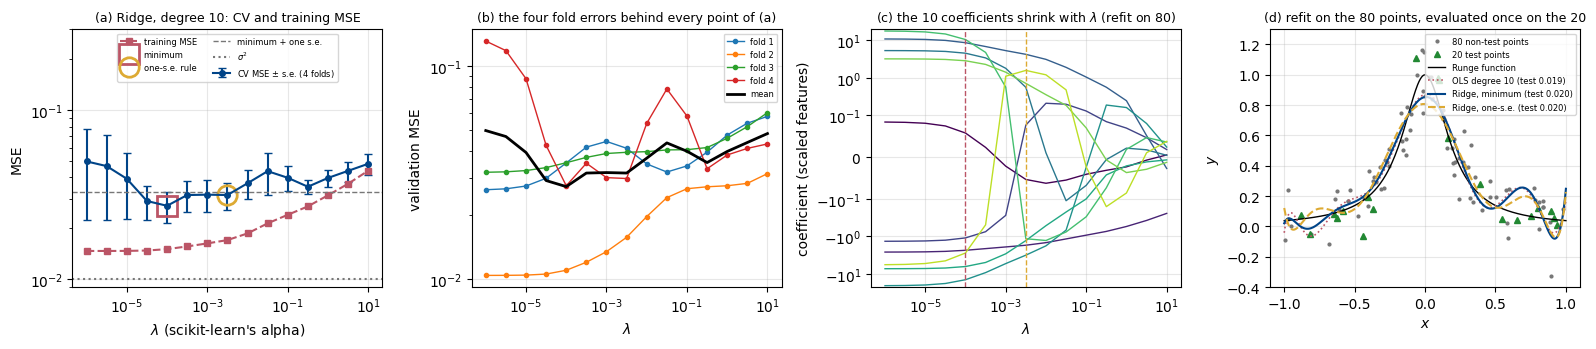

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
ax[0].errorbar(lambdas, cv_mse, yerr=cv_se, marker="o", ms=4, capsize=3, color=BLUE, label="CV MSE $\\pm$ s.e. (4 folds)")
ax[0].plot(lambdas, train_mse, "s--", ms=4, color=RED, label="training MSE")
ax[0].plot(lambdas[i_min], cv_mse[i_min], "s", mfc="none", mec=RED, mew=2, ms=14, label="minimum")
ax[0].plot(lambdas[i_one], cv_mse[i_one], "o", mfc="none", mec=YELLOW, mew=2, ms=14, label="one-s.e. rule")
ax[0].axhline(cv_mse[i_min] + cv_se[i_min], color=GREY, ls="--", lw=1, label="minimum + one s.e.")
ax[0].axhline(0.01, color=GREY, ls=":", label="$\\sigma^2$")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("$\\lambda$ (scikit-learn's alpha)"); ax[0].set_ylabel("MSE")
ax[0].set_ylim(0.009, 0.3); ax[0].legend(fontsize=6, loc="upper center", ncol=2); ax[0].grid(alpha=0.3)
ax[0].set_title(f"(a) Ridge, degree {degree}: CV and training MSE", fontsize=9)
for j in range(k):
    ax[1].plot(lambdas, fold_mse[:, j], "o-", ms=3, lw=1, label=f"fold {j + 1}")
ax[1].plot(lambdas, cv_mse, "k-", lw=2, label="mean")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("$\\lambda$"); ax[1].set_ylabel("validation MSE")
ax[1].legend(fontsize=6); ax[1].grid(alpha=0.3); ax[1].set_title("(b) the four fold errors behind every point of (a)", fontsize=9)
coefs = np.array([make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), Ridge(alpha=lam)).fit(X_train, y_train)[-1].coef_
                  for lam in lambdas])
for p in range(degree):
    ax[2].plot(lambdas, coefs[:, p], "-", lw=1, color=plt.cm.viridis(p / degree))
ax[2].axvline(lambdas[i_min], color=RED, ls="--", lw=1); ax[2].axvline(lambdas[i_one], color=YELLOW, ls="--", lw=1)
ax[2].set_xscale("log"); ax[2].set_yscale("symlog", linthresh=0.1); ax[2].set_xlabel("$\\lambda$"); ax[2].set_ylabel("coefficient (scaled features)")
ax[2].grid(alpha=0.3); ax[2].set_title(f"(c) the {degree} coefficients shrink with $\\lambda$ (refit on 80)", fontsize=9)
xx = np.linspace(-1, 1, 400).reshape(-1, 1)
ax[3].plot(X_train, y_train, ".", color=GREY, ms=4, label="80 non-test points")
ax[3].plot(X_test, y_test, "^", color=GREEN, ms=5, label="20 test points")
ax[3].plot(xx, 1 / (1 + 25 * xx ** 2), "-", color="black", lw=1, label="Runge function")
ax[3].plot(xx, ols.predict(xx), ":", color=RED, lw=1.2, label=f"OLS degree {degree} (test {mse(ols):.3f})")
ax[3].plot(xx, best.predict(xx), "-", color=BLUE, lw=1.5, label=f"Ridge, minimum (test {mse(best):.3f})")
ax[3].plot(xx, one_se.predict(xx), "--", color=YELLOW, lw=1.5, label=f"Ridge, one-s.e. (test {mse(one_se):.3f})")
ax[3].set_ylim(-0.4, 1.3); ax[3].set_xlabel("$x$"); ax[3].set_ylabel("$y$"); ax[3].legend(fontsize=6); ax[3].grid(alpha=0.3)
ax[3].set_title("(d) refit on the 80 points, evaluated once on the 20", fontsize=9)
fig.tight_layout()
fig.savefig("week44_ridge_cv.pdf"); fig.savefig("week44_ridge_cv.png", dpi=150)
plt.show()

**Reading the result.** Read the table from the top. At $\lambda\le10^{-5}$
the fold-4 error is $0.13$ to $0.09$ while folds 1–3 sit at $0.01$ to
$0.03$: fold 4 holds the right end point of the data, the degree-10
polynomial fitted to the other 60 points extrapolates there, and with no
penalty it extrapolates wildly — the overfitting side of the curve, with a
training MSE of $0.015$ that says nothing about it. From $\lambda=10^{-2}$
upwards every fold error rises together and so does the training MSE: the
underfitting side. The minimum is at $\lambda=10^{-4}$, CV MSE
$0.0272\pm0.0057$; five values, from $3\cdot10^{-5}$ to $3\cdot10^{-3}$,
are within one standard error of it, and the one-standard-error rule
picks the largest, $\lambda=3\cdot10^{-3}$ at $0.0315$ — two decades of
$\lambda$ that the 80 points cannot tell apart, which is the honest
resolution of the experiment. Panel (b) shows why the error bars are what
they are: fold 2 (the fold without end points) is near the noise floor
everywhere, fold 4 is the one that moves. Panel (c) is the mechanism —
the ten scaled coefficients, up to $\pm10$ without a penalty, shrink
through the chosen $\lambda$'s towards zero. Panel (d) and the last cell
are step 6: refitted on the 80 points, the minimum and the one-s.e. models
both give a test MSE of $0.0201$ on the 20 test points, below their CV
estimates (the refit has 80 points, the fold models had 60 — Part A.5),
and OLS gives $0.0189$: on *20* test points the three cannot be
separated, since even a perfect model's test MSE has a standard deviation
of $\sigma^2\sqrt{2/20}\approx0.003$, and that is the last thing the
table teaches — the test set measures, it does not select, and the
selection was made where the error bars are: in the four folds.

What goes into the report: the table (or the heat map, when there are two
hyperparameters) with the per-fold numbers available, panel (a) with the
error bars and both marks, the chosen $\lambda$ with its reason, and the
test number once. Case 2 does the same for the network, with $\gamma$ and
$\lambda$ on a grid.

## Case 1: the six questions of exercise 1 — pencil and paper, in groups

Fifteen minutes in your group, then plenum, one question at a time. Nothing
is computed in Case 1.

**a)** State in one sentence what the $k$-fold cross-validation error
estimates (Section 2.12): the error of *which* model, trained on how much
data, evaluated on what? Why is it an estimate of the generalisation error
of the training *procedure* rather than of the one network you finally
train on all the data?

**b)** With $k$ folds you obtain $k$ numbers $e_1,\dots,e_k$. Give the mean
and its standard error, $\bar e\pm s/\sqrt{k}$, and explain why the $k$
numbers are not independent (two training sets share $(k-2)/(k-1)$ of their
samples), so that this standard error is optimistic. What happens to the
bias and the variance of the estimate as $k$ goes from $2$ to $n$?

**c)** Scaling. You standardise the inputs before training. Explain why the
scaler must be *fitted inside each fold* on the training part only, and name
one concrete number that leaks if it is fitted on all the data first. How
does a `scikit-learn` `Pipeline` guarantee it, in one sentence?

**d)** A colleague trains ten networks with ten learning rates, reports the
test MSE of each, and writes "the best learning rate is $0.01$, with a test
MSE of $0.0094$". Name the two things that are wrong with that sentence and
write the honest version of it.

**e)** Early stopping. Explain why the number of epochs is a hyperparameter
like any other, how a validation fold is used to choose it, and why the
training error is useless for that purpose.

**f)** The one-standard-error rule (Section 3.14). You have the
cross-validated MSE and its standard error for
$\lambda\in\{0,10^{-5},\dots,10^{-2}\}$. State the rule and explain why it
prefers the *more* regularised model among those within one standard error
of the best — and what "more regularised" means for a network when the grid
is over hidden units rather than over $\lambda$.

*Your group's answers (LaTeX in markdown is fine):*

a)

b)

c)

d)

e)

f)

## Case 2: your network inside scikit-learn's cross-validation, in six steps

The data cell of Project 2, part b), verbatim: $n=100$ points, $x$ uniform
on $[-1,1]$, $y=1/(1+25x^2)+\varepsilon$ with $\sigma=0.1$, seed 2026. One
`KFold(5, shuffle=True, random_state=2026)` object is used for *everything*
below, so that every comparison — network against network, network against
polynomial — is on the same folds.

The week-41 network is reproduced in the next cell so that the notebook
runs on its own (`create_layers`, `feed_forward`, `backpropagation`,
`train`, `predict`). In the exercises, replace it by your Project 2 code.

In [8]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history



train_dense, predict_dense = train, predict      # the names used in the wrapper below

In [9]:
def runge_project2(n=100, sigma=0.1, seed=2026):
    """The data cell of Project 2, part b), verbatim: x uniform on [-1, 1], y = 1/(1 + 25 x^2) + N(0, sigma^2)."""
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(-1.0, 1.0, n))
    y = 1.0 / (1.0 + 25.0 * x ** 2) + rng.normal(0.0, sigma, n)
    return x.reshape(-1, 1), y



X, y = runge_project2()
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"{len(y)} points; the five validation folds have sizes {[len(val) for _, val in cv.split(X)]}")

100 points; the five validation folds have sizes [20, 20, 20, 20, 20]


### Step 1: the wrapper — your network as a scikit-learn estimator

The three rules of Part A, applied to the week-41 code. `__init__` stores
the hyperparameters under their own names; `fit` builds the layers from the
seed, trains, stores the result in `self.layers_` and returns `self`;
`predict` runs the forward pass and returns a 1D array. `BaseEstimator`
supplies `get_params`/`set_params` (which is how `GridSearchCV` will set
`gamma` and `lmbd`), `RegressorMixin` supplies `score` (the $R^2$).

**Checkpoint:** `fit` on all 100 points and the training MSE must agree
with what your own training loop prints for the same settings, to every
digit — here with the week-41 `train` called directly.

In [10]:
class Week41Regressor(BaseEstimator, RegressorMixin):
    """The week-41 network with the scikit-learn estimator interface (exercise 2a of week 44).

    Rule 1: __init__ stores its keyword arguments under the same names and
    does nothing else -- BaseEstimator then supplies get_params/set_params,
    which is how GridSearchCV sets gamma and lmbd, and clone() gives every
    fold a fresh, untrained copy.  Rule 2: fit does all the work, stores the
    result in attributes ending in an underscore, and returns self.  Rule 3:
    predict returns a 1D array; RegressorMixin supplies score() (the R^2).
    """

    def __init__(self, hidden=(50,), activation="sigmoid", gamma=0.03, lmbd=0.0, epochs=1000, batch_size=10, seed=2026):
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):
        sizes = [X.shape[1], *self.hidden, 1]
        layers = create_layers(sizes, self.activation, np.random.default_rng(self.seed))
        self.layers_, self.history_ = train_dense(X, y.reshape(-1, 1), layers, self.activation, "mse", gamma=self.gamma,
                                                  epochs=self.epochs, batch_size=self.batch_size, lmbd2=self.lmbd,
                                                  rng=np.random.default_rng(self.seed))
        return self

    def predict(self, X):
        return predict_dense(X, self.layers_, self.activation, "mse")[:, 0]


def cv_pipeline(**kwargs):
    """StandardScaler inside the fold, then the network: cross-validating the pipeline refits the scaler on every training part."""
    return make_pipeline(StandardScaler(), Week41Regressor(**kwargs))


In [11]:
est = Week41Regressor().fit(X, y)
mse_wrapper = np.mean((est.predict(X) - y) ** 2)
layers = create_layers([1, 50, 1], "sigmoid", np.random.default_rng(SEED))
layers, _ = train(X, y.reshape(-1, 1), layers, "sigmoid", "mse", gamma=0.03, epochs=1000, batch_size=10, rng=np.random.default_rng(SEED))
mse_direct = np.mean((predict(X, layers, "sigmoid", "mse")[:, 0] - y) ** 2)
print(f"training MSE through the wrapper {mse_wrapper:.6f}, through the week-41 loop {mse_direct:.6f}, identical: {np.isclose(mse_wrapper, mse_direct)}")
print("the parameters GridSearchCV can set:", list(cv_pipeline().get_params().keys())[-7:])

training MSE through the wrapper 0.046478, through the week-41 loop 0.046478, identical: True
the parameters GridSearchCV can set: ['week41regressor__activation', 'week41regressor__batch_size', 'week41regressor__epochs', 'week41regressor__gamma', 'week41regressor__hidden', 'week41regressor__lmbd', 'week41regressor__seed']


### Step 2: a first look — `cross_val_score` and `cross_validate`

The pipeline puts the scaler *inside* each fold. `cross_val_score` returns
one score per fold, as a negative MSE; `cross_validate` adds the training
scores and the fit times.

**Checkpoint:** the training MSE is below the CV MSE, both are above the
noise floor $\sigma^2=0.01$, and the five folds differ by a factor of about
three — the spread that the standard error summarises.

In [12]:
def cv_first_look(X, y, cv):
    """Step 2 of the case: cross_val_score (one negative MSE per fold) and cross_validate with the training scores."""
    net = cv_pipeline()
    scores = -cross_val_score(net, X, y, cv=cv, scoring="neg_mean_squared_error")
    res = cross_validate(net, X, y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
    return {"val": scores, "train": -res["train_score"], "fit_time": res["fit_time"],
            "mean": scores.mean(), "se": scores.std(ddof=1) / np.sqrt(len(scores))}


In [13]:
first = cv_first_look(X, y, cv)
print(f"validation MSE per fold: {first['val']}")
print(f"training MSE per fold:   {first['train']}")
print(f"5-fold CV MSE {first['mean']:.4f} +/- {first['se']:.4f};  training {first['train'].mean():.4f};  {first['fit_time'].mean():.2f} s per fit")

validation MSE per fold: [0.0313 0.049  0.0163 0.0334 0.0371]
training MSE per fold:   [0.025  0.0306 0.03   0.0255 0.0243]
5-fold CV MSE 0.0334 +/- 0.0053;  training 0.0271;  0.71 s per fit


### Step 3: the grid — `GridSearchCV` over the learning rate and the penalty

`GridSearchCV` fits every combination on every fold and stores everything
in `cv_results_`; with `refit=True` (the default) it retrains the best
combination on *all* 100 points and exposes it as `best_estimator_`. The
standard error is `std_test_score / np.sqrt(k - 1)` (`ddof=0`); the cells
within one standard error of the minimum are the ones the data cannot tell
apart, and the one-standard-error rule picks the most regularised of them.

**Checkpoint:** which hyperparameter matters most on this grid? Where has
the optimiser not converged in 1000 epochs?

In [14]:
def cv_grid(X, y, cv, gammas=(0.001, 0.003, 0.01, 0.03, 0.1), lambdas=(0.0, 1e-5, 1e-4, 1e-3, 1e-2)):
    """Step 3: GridSearchCV over the learning rate and the penalty; CV MSE, its standard error, the training MSE, the one-s.e. set."""
    k = cv.get_n_splits()
    search = GridSearchCV(cv_pipeline(), {"week41regressor__gamma": list(gammas), "week41regressor__lmbd": list(lambdas)},
                          cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
    search.fit(X, y)
    r = search.cv_results_
    shape = (len(gammas), len(lambdas))
    mse = -r["mean_test_score"].reshape(shape)
    se = r["std_test_score"].reshape(shape) / np.sqrt(k - 1)          # std_test_score uses ddof=0: s/sqrt(k) = std/sqrt(k-1)
    tr = -r["mean_train_score"].reshape(shape)
    i_best = np.unravel_index(np.argmin(mse), shape)
    within = mse <= mse[i_best] + se[i_best]
    # the one-standard-error rule: among the cells within one s.e., the largest penalty, then the smallest learning rate
    cand = [(j, i) for i in range(shape[0]) for j in range(shape[1]) if within[i, j]]
    j1, i1 = max(cand, key=lambda t: (lambdas[t[0]], -gammas[t[1]]))
    return {"search": search, "mse": mse, "se": se, "train": tr, "best": i_best, "within": within, "one_se": (i1, j1),
            "gammas": list(gammas), "lambdas": list(lambdas), "fit_time": r["mean_fit_time"].reshape(shape)}


In [15]:
t0 = time.time()
grid = cv_grid(X, y, cv)
bi, bj = grid["best"]; oi, oj = grid["one_se"]
print(f"{grid['search'].n_splits_}-fold grid, {len(grid['gammas']) * len(grid['lambdas'])} points, {time.time() - t0:.0f} s")
print("CV MSE (rows gamma, columns lambda):\n", np.round(grid["mse"], 4))
print("standard error:\n", np.round(grid["se"], 4))
print("training MSE:\n", np.round(grid["train"], 4))
print(f"minimum: gamma {grid['gammas'][bi]:g}, lambda {grid['lambdas'][bj]:g}: {grid['mse'][bi, bj]:.4f} +/- {grid['se'][bi, bj]:.4f}")
print("within one standard error of the minimum:\n", grid["within"])
print(f"one-standard-error rule: gamma {grid['gammas'][oi]:g}, lambda {grid['lambdas'][oj]:g}: {grid['mse'][oi, oj]:.4f}")
print("best_estimator_ is the pipeline refit on all 100 points:", grid["search"].best_estimator_)

5-fold grid, 25 points, 91 s
CV MSE (rows gamma, columns lambda):
 [[0.1054 0.1054 0.1054 0.1055 0.1059]
 [0.1028 0.1028 0.1029 0.1033 0.1058]
 [0.0819 0.082  0.0827 0.0893 0.1066]
 [0.0334 0.0335 0.0345 0.0435 0.1074]
 [0.0263 0.0267 0.0303 0.054  0.1114]]
standard error:
 [[0.0112 0.0112 0.0112 0.0112 0.0111]
 [0.0111 0.0111 0.0111 0.0111 0.0109]
 [0.011  0.011  0.011  0.0114 0.0106]
 [0.0053 0.0053 0.0054 0.006  0.01  ]
 [0.0041 0.0042 0.0053 0.0064 0.0099]]
training MSE:
 [[0.0996 0.0996 0.0996 0.0997 0.1003]
 [0.0964 0.0964 0.0965 0.0971 0.1004]
 [0.0738 0.0739 0.0747 0.0819 0.1018]
 [0.0271 0.0272 0.0281 0.0383 0.1029]
 [0.0214 0.0217 0.0248 0.0497 0.1054]]
minimum: gamma 0.1, lambda 0: 0.0263 +/- 0.0041
within one standard error of the minimum:
 [[False False False False False]
 [False False False False False]
 [False False False False False]
 [False False False False False]
 [ True  True  True False False]]
one-standard-error rule: gamma 0.1, lambda 0.0001: 0.0303
best_estimato

### Step 4 (optional): validation curves — the width and the number of epochs

Cross-validating the architecture and the number of epochs is optional in
the exercises and in Project 2; this step shows how it is done with the
same machinery as step 3. `validation_curve` varies one hyperparameter
with the others fixed and returns the training and validation scores of
every fold, shape `(len(param_range), k)`. Over the hidden units it tells
you whether the one- and two-layer networks of Project 2 are
distinguishable within the error bars; over the epochs it is early
stopping done the expensive way (a full training per value) — the epoch at
which the CV curve is lowest is the chosen number of epochs.

**Checkpoint:** the training curve only falls. Where does the CV curve stop
falling — and does it, within 3000 epochs at $\gamma=0.03$?

In [16]:
def cv_curves(X, y, cv, hiddens=((5,), (10,), (25,), (50,), (100,)), epochs=(50, 100, 300, 1000, 3000), gamma=0.03, lmbd=0.0):
    """Step 4: validation_curve over the number of hidden units and over the number of epochs (early stopping as a hyperparameter)."""
    out = {}
    tr, va = validation_curve(cv_pipeline(gamma=gamma, lmbd=lmbd), X, y, param_name="week41regressor__hidden",
                              param_range=list(hiddens), cv=cv, scoring="neg_mean_squared_error")
    out["hidden"] = {"values": [h[0] for h in hiddens], "train": -tr, "val": -va,
                     "n_params": [1 * h[0] + h[0] + h[0] * 1 + 1 for h in hiddens]}
    tr, va = validation_curve(cv_pipeline(gamma=gamma, lmbd=lmbd), X, y, param_name="week41regressor__epochs",
                              param_range=list(epochs), cv=cv, scoring="neg_mean_squared_error")
    out["epochs"] = {"values": list(epochs), "train": -tr, "val": -va}
    return out


In [17]:
t0 = time.time()
curves = cv_curves(X, y, cv)
h, e = curves["hidden"], curves["epochs"]
print(f"{time.time() - t0:.0f} s")
print("hidden units:", h["values"])
print("  CV MSE      ", np.round(h["val"].mean(1), 4), "+/-", np.round(h["val"].std(1, ddof=1) / np.sqrt(5), 4))
print("  training MSE", np.round(h["train"].mean(1), 4), "   parameters", h["n_params"])
print("epochs:      ", e["values"])
print("  CV MSE      ", np.round(e["val"].mean(1), 4), "+/-", np.round(e["val"].std(1, ddof=1) / np.sqrt(5), 4))
print("  training MSE", np.round(e["train"].mean(1), 4))

34 s
hidden units: [5, 10, 25, 50, 100]
  CV MSE       [0.0405 0.0524 0.0399 0.0334 0.036 ] +/- [0.0055 0.0088 0.0047 0.0053 0.0046]
  training MSE [0.0379 0.047  0.0356 0.0271 0.0304]    parameters [16, 31, 76, 151, 301]
epochs:       [50, 100, 300, 1000, 3000]
  CV MSE       [0.1043 0.1033 0.087  0.0334 0.0245] +/- [0.0111 0.0099 0.0107 0.0053 0.003 ]
  training MSE [0.0989 0.0977 0.0787 0.0271 0.0197]


### Step 5: the benchmark — OLS and Ridge polynomials on the same folds

Project 1 fitted this function with polynomials; a network that cannot beat
them is not worth its cost. The same `cv` object, `GridSearchCV` over the
degree (and, for Ridge, the penalty — `scikit-learn`'s `alpha` is our
$n\lambda$, Section 3.14).

In [18]:
def cv_polynomial(X, y, cv, degrees=range(1, 16), ridge_lambdas=(1e-6, 1e-4, 1e-2, 1.0)):
    """Step 5: OLS and Ridge polynomials on the SAME folds -- the Project 1 benchmark for the network."""
    k = cv.get_n_splits()
    ols = GridSearchCV(make_pipeline(StandardScaler(), PolynomialFeatures(), LinearRegression()),
                       {"polynomialfeatures__degree": list(degrees)}, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
    ols.fit(X, y)
    ridge = GridSearchCV(make_pipeline(StandardScaler(), PolynomialFeatures(), Ridge()),
                         {"polynomialfeatures__degree": list(degrees), "ridge__alpha": [len(y) * l for l in ridge_lambdas]},
                         cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
    ridge.fit(X, y)
    r = ols.cv_results_
    return {"ols": ols, "ridge": ridge, "degrees": list(degrees), "ols_mse": -r["mean_test_score"],
            "ols_se": r["std_test_score"] / np.sqrt(k - 1), "ols_train": -r["mean_train_score"]}


In [19]:
poly = cv_polynomial(X, y, cv)
d = poly["ols"].best_params_["polynomialfeatures__degree"]
print("OLS, CV MSE by degree:   ", np.round(poly["ols_mse"], 4))
print("OLS, standard error:     ", np.round(poly["ols_se"], 4))
print("OLS, training MSE:       ", np.round(poly["ols_train"], 4))
print(f"OLS: best degree {d}, CV MSE {-poly['ols'].best_score_:.4f} +/- {poly['ols_se'][d - 1]:.4f}, {d + 1} parameters")
print(f"Ridge: {poly['ridge'].best_params_} (alpha = n lambda), CV MSE {-poly['ridge'].best_score_:.4f}")
print(f"the network: untuned {first['mean']:.4f} +/- {first['se']:.4f}, best grid point {grid['mse'][bi, bj]:.4f} +/- {grid['se'][bi, bj]:.4f}, "
      f"151 parameters, {grid['fit_time'].mean():.2f} s per fit against {poly['ols'].cv_results_['mean_fit_time'].mean() * 1e3:.1f} ms")

OLS, CV MSE by degree:    [0.1067 0.0541 0.0574 0.0343 0.035  0.0273 0.0312 0.0225 0.0238 0.024
 0.0211 0.0426 0.064  0.0392 0.0923]
OLS, standard error:      [0.0108 0.0058 0.0059 0.0037 0.0039 0.0025 0.0046 0.0017 0.0012 0.0029
 0.0032 0.0188 0.0367 0.0113 0.0584]
OLS, training MSE:        [0.1019 0.052  0.0512 0.0303 0.0301 0.0214 0.0212 0.0164 0.0161 0.0149
 0.0143 0.013  0.0128 0.0136 0.0138]
OLS: best degree 11, CV MSE 0.0211 +/- 0.0032, 12 parameters
Ridge: {'polynomialfeatures__degree': 11, 'ridge__alpha': 0.01} (alpha = n lambda), CV MSE 0.0210
the network: untuned 0.0334 +/- 0.0053, best grid point 0.0263 +/- 0.0041, 151 parameters, 0.72 s per fit against 2.6 ms


### Step 6: the test set, once

A fresh set of 100 points (seed 1) that nothing above has seen.
`best_estimator_` — the winning pipeline refit on all 100 training points —
is evaluated on it once, and so are the polynomials. No going back to the
grid afterwards.

In [20]:
def cv_test_once(search, X_test, y_test):
    """Step 6: best_estimator_ (the winner refit on all training points) on a test set it has never seen, once."""
    return float(np.mean((search.best_estimator_.predict(X_test) - y_test) ** 2))


In [21]:
X_test, y_test = runge_project2(seed=1)
print(f"test MSE, once: network best_estimator_ {cv_test_once(grid['search'], X_test, y_test):.4f}, "
      f"OLS degree {d} {cv_test_once(poly['ols'], X_test, y_test):.4f}, Ridge {cv_test_once(poly['ridge'], X_test, y_test):.4f}")
print(f"for comparison, the CV scores were {grid['mse'][bi, bj]:.4f} (network) and {-poly['ols'].best_score_:.4f} (OLS)")

test MSE, once: network best_estimator_ 0.0148, OLS degree 11 0.0133, Ridge 0.0135
for comparison, the CV scores were 0.0263 (network) and 0.0211 (OLS)


In [22]:
def fig_cv(grid, curves, poly, first, fname="week44_cv.pdf"):
    """(a) the grid as a heat map, (b) CV MSE against gamma with error bars, (c) hidden units, (d) epochs, (e) the polynomial benchmark."""
    fig, ax = plt.subplots(1, 5, figsize=(16, 3.4))
    g, l = grid["gammas"], grid["lambdas"]
    im = ax[0].imshow(grid["mse"], cmap="viridis_r", origin="lower")
    ax[0].set_xticks(range(len(l))); ax[0].set_xticklabels([f"{v:g}" for v in l], fontsize=7)
    ax[0].set_yticks(range(len(g))); ax[0].set_yticklabels([f"{v:g}" for v in g], fontsize=7)
    ax[0].set_xlabel("$\\lambda$"); ax[0].set_ylabel("$\\gamma$")
    for i in range(len(g)):
        for j in range(len(l)):
            ax[0].text(j, i, f"{grid['mse'][i, j]:.3f}", ha="center", va="center", fontsize=6,
                       color="white" if grid["mse"][i, j] > 0.6 * grid["mse"].max() else "black",
                       fontweight="bold" if grid["within"][i, j] else "normal")
    bi, bj = grid["best"]; oi, oj = grid["one_se"]
    ax[0].plot(bj, bi, "s", mfc="none", mec=RED, mew=2, ms=16)
    ax[0].plot(oj, oi, "o", mfc="none", mec=YELLOW, mew=2, ms=16)
    ax[0].set_title("(a) CV MSE; bold = within 1 s.e.\nred: minimum, yellow: one-s.e. rule", fontsize=9)
    for j, lam in enumerate(l):
        ax[1].errorbar(g, grid["mse"][:, j], yerr=grid["se"][:, j], marker="o", ms=3, capsize=2, label=f"$\\lambda={lam:g}$")
    ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("$\\gamma$"); ax[1].set_ylabel("CV MSE $\\pm$ s.e.")
    ax[1].axhline(0.01, color=GREY, ls=":", label="$\\sigma^2$"); ax[1].legend(fontsize=6); ax[1].grid(alpha=0.3)
    ax[1].set_title("(b) the same grid, read along $\\gamma$", fontsize=9)
    h = curves["hidden"]
    ax[2].errorbar(h["values"], h["val"].mean(1), yerr=h["val"].std(1, ddof=1) / np.sqrt(h["val"].shape[1]), marker="o", ms=4,
                   capsize=2, color=BLUE, label="CV")
    ax[2].plot(h["values"], h["train"].mean(1), "s--", ms=4, color=RED, label="training")
    ax[2].set_xscale("log"); ax[2].set_xlabel("hidden units ($\\gamma=0.03$, $\\lambda=0$)"); ax[2].set_ylabel("MSE")
    ax[2].axhline(0.01, color=GREY, ls=":"); ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3)
    ax[2].set_title("(c) validation curve: width", fontsize=9)
    e = curves["epochs"]
    for k in range(e["val"].shape[1]):
        ax[3].plot(e["values"], e["val"][:, k], "-", color=BLUE, alpha=0.35, lw=1)
    ax[3].plot(e["values"], e["val"].mean(1), "o-", color=BLUE, ms=4, label="CV, mean and folds")
    ax[3].plot(e["values"], e["train"].mean(1), "s--", color=RED, ms=4, label="training")
    ax[3].set_xscale("log"); ax[3].set_xlabel("epochs"); ax[3].set_ylabel("MSE"); ax[3].axhline(0.01, color=GREY, ls=":")
    ax[3].legend(fontsize=7); ax[3].grid(alpha=0.3); ax[3].set_title("(d) validation curve: epochs", fontsize=9)
    ax[4].errorbar(poly["degrees"], poly["ols_mse"], yerr=poly["ols_se"], marker="o", ms=4, capsize=2, color=GREEN, label="OLS, CV")
    ax[4].plot(poly["degrees"], poly["ols_train"], "s--", ms=4, color=RED, label="OLS, training")
    ax[4].axhline(first["mean"], color=BLUE, ls="-", label="network, untuned")
    ax[4].axhline(grid["mse"][grid["best"]], color=BLUE, ls="--", label="network, best grid point")
    ax[4].set_yscale("log"); ax[4].set_xlabel("polynomial degree"); ax[4].set_ylabel("MSE"); ax[4].axhline(0.01, color=GREY, ls=":")
    ax[4].legend(fontsize=6); ax[4].grid(alpha=0.3); ax[4].set_title("(e) the Project 1 benchmark, same folds", fontsize=9)
    fig.tight_layout()
    fig.savefig(fname); fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)


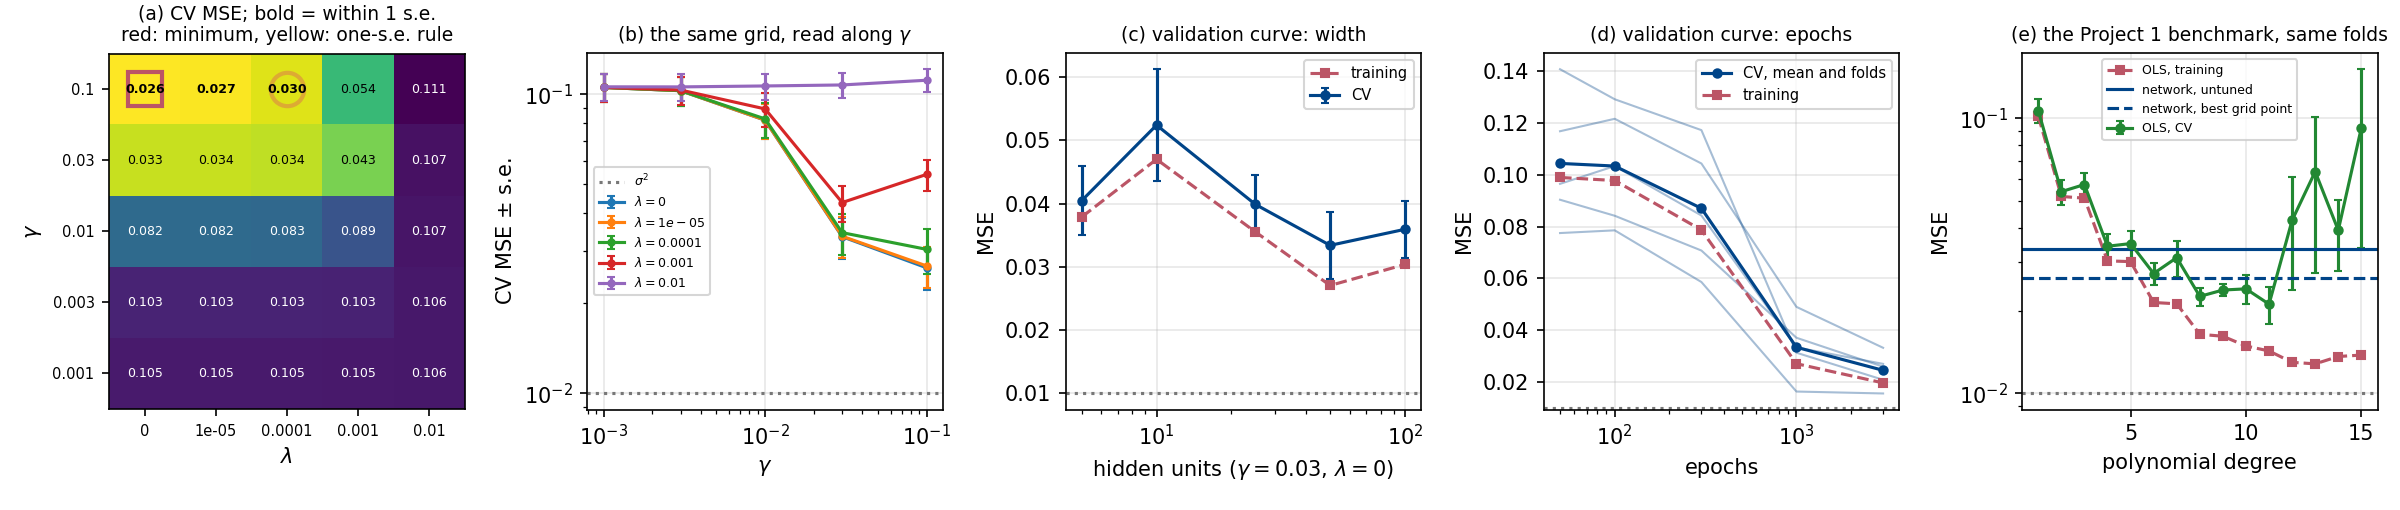

In [23]:
fig_cv(grid, curves, poly, first)
Image("week44_cv.png", width=1100)

**What you should find.** (a) The learning rate matters most: at
$\gamma=0.001$ and $0.003$ the network has not converged in 1000 epochs (CV
MSE $0.105$, the variance of $y$ — it predicts the mean), at $\gamma=0.1$ it
has; the penalty does nothing until $10^{-2}$, where it hurts. The minimum
is at $\gamma=0.1$, $\lambda=0$ with $0.0263\pm0.0041$; three cells are
within one standard error and the one-standard-error rule picks the largest
penalty among them, $\lambda=10^{-4}$ — a weak preference, since the data
cannot see the difference. (c) Over the width the CV curve moves between
$0.033$ and $0.052$ with error bars of $0.005$–$0.009$: no trend the data
resolve, and the training curve only slightly below — at this $\gamma$ and
1000 epochs the width is not what limits the fit. (d) The CV curve over
the epochs is still falling at 3000: this network is under-trained, not
over-trained, and early stopping would not stop it yet. (e) OLS of degree
11 reaches $0.0211\pm0.0032$ on the same folds; the untuned network is
worse than the polynomial, the tuned one within one standard error of it,
with 151 parameters against 12 and a fit a thousand times slower.

The test set, once: network $0.0148$, OLS $0.0133$, Ridge $0.0135$ — all
*below* their CV scores. Two effects compete: the refit on 100 points
instead of 80 (more data, and 25 % more SGD steps per epoch) pulls the
error down, the selection of the minimum of 25 noisy estimates pushes the
CV score down; here the first wins, on another test draw it might not. One
test number has no error bar either.

## Case 2: do you have the insight?

Discuss in your group, then in plenum.

1. `GridSearchCV` refits the best point on all 100 points. Why is the CV
   error of that point *not* the error you should expect from
   `best_estimator_` — in which direction is it off, and for two different
   reasons?
2. The validation curve over the epochs is still falling at 3000. Does that
   mean more epochs are always better for this network? What would you do
   before concluding?
3. The polynomial of degree 11 and the tuned network are within one
   standard error of each other. Which do you report as "better" in
   Project 2, and what sentence goes with the number?
4. Someone runs the grid with `cv=KFold(5)` without `shuffle=True`. The data
   cell sorted $x$. What goes wrong?

**What we hope you say.** (1) The CV score is pessimistic because the fold
models had 80 points instead of 100, and optimistic because it is the
minimum of 25 noisy estimates; which wins depends on the problem — here the
test MSE came out below the CV score, so the first did. (2) No: at
$\gamma=0.03$ the optimiser is slow and the curve says "not converged";
raise $\gamma$ (the grid did) or add momentum, then look again — a
validation curve over epochs is a statement about *this* optimiser at
*this* learning rate. (3) Neither: report both with their error bars and
say they cannot be told apart on 100 points; prefer the polynomial on
simplicity and speed unless the network wins elsewhere. (4) The folds are
contiguous intervals of $x$: every fold model extrapolates to a region it
never saw, the CV error is pessimistic, and the chosen hyperparameters are
the ones that extrapolate least badly, not the ones that fit best. Shuffle.

## Only a mention: the same with PyTorch and Keras

Nothing changes in the theory, and `KFold` only makes indices. Ten lines
around any training function — the Monday CNN included — do the job; the
discipline (scaler inside the fold, a fresh model per fold, the test set
once) is yours to keep, since nothing enforces it:

```python
errors = []
for train_idx, val_idx in KFold(5, shuffle=True, random_state=2026).split(X):
    scaler = StandardScaler().fit(X[train_idx])              # inside the fold
    net = build_torch_model()                                # a fresh model
    train_torch(net, scaler.transform(X[train_idx]), y[train_idx], epochs=...)
    errors.append(mse_torch(net, scaler.transform(X[val_idx]), y[val_idx]))
print(np.mean(errors), np.std(errors, ddof=1) / np.sqrt(5))
```

Or make the framework model a `scikit-learn` estimator and reuse everything
above unchanged: `skorch.NeuralNetRegressor(module, lr=..., max_epochs=...)`
wraps a PyTorch module, `scikeras.wrappers.KerasRegressor(build_fn, ...)`
wraps a Keras model; both obey the three rules, so `GridSearchCV` and
`Pipeline` work as in Case 2.

Both frameworks also offer a *single* validation split with early stopping
built in — `model.fit(X, y, validation_split=0.2,
callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])`
in Keras, `torch.utils.data.random_split` and a hand-written loop in
PyTorch — cheaper than $k$ folds and the usual choice when one training run
costs minutes, with no standard error. The warnings carry over:
`validation_split` takes the *last* fraction of the data unshuffled; scale
inside the split; the number of epochs early stopping reports is a
hyperparameter chosen on that split; the test set is still touched once.
None of this is needed for Project 2.

---

## Case 1: the answers we hope for (read after the plenum)

**a)** The expected error, on data from the same distribution never seen in
training, of the *procedure* "this architecture with these hyperparameters,
trained this way on $n(k-1)/k$ points" — averaged over which points those
are. It is about the procedure because the $k$ fold models are different
networks (different training sets, same recipe) that are averaged and
discarded; the network you keep is a new fit on all $n$ points, which CV
never evaluated. CV estimates how well the recipe generalises, slightly
pessimistically because the fold models had fewer points.

**b)** $\bar e=\frac1k\sum_j e_j$, $s^2=\frac{1}{k-1}\sum_j(e_j-\bar e)^2$,
standard error $s/\sqrt k$ (Eq. 3.93). Two training sets each omit one fold
and share the other $k-2$ of the $k-1$ folds they contain: a fraction
$(k-2)/(k-1)$ in common, $3/4$ for $k=5$. Positively correlated fold errors
have a larger variance of the mean than independent ones, so $s/\sqrt k$ is
optimistic (too small). $k=2$: training sets of $n/2$, the estimate is
pessimistic (biased upwards) but the two fold errors are nearly
independent; $k=n$: no size bias and no fold randomness, but $n$ almost
identical training sets, highly correlated errors, high variance, and $n$
fits.

**c)** Fitted on all the data, the scaler has seen the mean and the standard
deviation of the held-out fold, so information about the validation points
enters the training and the held-out fold is no longer "future data". The
numbers that leak: the fold's mean and variance of $x$ (and of $y$ if the
targets are scaled). A `Pipeline` refits *every* step on the training part
of each fold when the library calls `fit`, and uses the stored statistics
when it calls `predict` on the held-out part.

**d)** First, the learning rate was chosen *on the test set*: the test MSE
was minimised over ten candidates, so $0.0094$ is the minimum of ten noisy
numbers and no longer estimates the error of anything. Second, there is no
uncertainty: ten single numbers, no standard error, no statement of how
different $0.0094$ is from the second best. Honest version: "Of ten
learning rates, five-fold cross-validation on the training data selected
$\gamma=0.01$ with a CV MSE of $x\pm s$ (training MSE $y$); the network
refitted at $\gamma=0.01$ on all training data has a test MSE of $z$,
computed once."

**e)** The number of epochs changes the fitted function exactly as $\lambda$
or the width does — a network trained for 100 epochs and one trained for
3000 are different models — and it cannot be chosen by the training error,
which is non-increasing in the epochs by construction. Hold out a
validation fold, record its error after every epoch (or every few), take
the epoch at which it is smallest, and train the final model for that many
epochs (or keep the weights of that epoch). Averaged over folds this is a
validation curve over epochs — step 4 above.

**f)** $\lambda_{1\mathrm{SE}}=\max\{\lambda:\mathrm{CV}(\lambda)\le
\mathrm{CV}(\lambda_{\min})+\mathrm{SE}(\lambda_{\min})\}$: the largest
penalty whose CV error is within one standard error of the best. The models
in that set cannot be told apart by the data, so the improvement of the
less regularised one is not believed, and the simpler model has lower
variance (and, for the Lasso, fewer features). Over hidden units "more
regularised" means *fewer* units — the smallest network within one standard
error of the best; over epochs, the fewest epochs.